In this notebook, clustering (KMens, Agglomerative Clustering and Gaussian Mixture Models) algorithms are applied to data taken from the latent space of an Autoencoder network. This solution is used instead of PCA to see if a Nearual Network approach to compress data provides better results in terms of data representation. 

The code is tested on the $\ge 3$ hits dataset of Background and TGFs.

# 00 - General operations

In [1]:
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd 

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, normalized_mutual_info_score, adjusted_rand_score
from sklearn.preprocessing import PowerTransformer

import tensorflow as tf

import sys
from pathlib import Path
sys.path.append(str(Path("../../../src/utils").resolve()))
from dataset_balancing import balance_dataset
sys.path.append(str(Path("../../../src/models").resolve()))
from autoencoder import AutoEncoder

Set the random seed for reproducibility:

In [2]:
random_state = 42
np.random.seed(random_state)

General control parameters are defined:
- the dimension of the latent space of the encoder
- the dimension of the hidden layers
- the batch size
- the min number of samples in the balanced dataset
- particle family mapping dictionare
- flag to decide if the clustering will be performed on families rather than single particle types
- correlation value threshold for dropping feature higly correlated 
- test data size

In [3]:
latent_space_dim = 10
hidden_dims = (64, 32, latent_space_dim)
# batch_size = 256

n_samples_min = 2000

families_dict = {
    # Neutral_Background
    "AlbedoPhotons" : "Neutral_Background",
    "AtmosphericNeutrons" : "Neutral_Background",
    "CosmicPhotons" : "Neutral_Background",

    # TEMP: tgf
    "TGF": "Neutral_Background",
    
    # EM_Primary 
    "PrimaryElectrons" : "EM_Primary",
    "PrimaryPositrons" : "EM_Primary",

    # EM_Secondary
    "SecondaryElectrons" : "EM_Secondary",
    "SecondaryPositrons" : "EM_Secondary",

    # Hadronic_Heavy
    "PrimaryProtons" : "Hadronic_Heavy",
    "PrimaryAlphas" : "Hadronic_Heavy",
    "SecondaryProtonsUpward" : "Hadronic_Heavy",
    "SecondaryProtonsDownward" : "Hadronic_Heavy"
}
FAMILY_CLUSTERING = True

corr_threshold = 0.90

test_size = 0.2

lr = 1e-3

# 01 - Data pre-processing

In this section data are loaded and balanced. Feature higly correlated are dropped in the dataset. 

## Data Loading

In [4]:
file_path = "../../../data/Engineered_Datasets/"
ds = pd.read_csv(file_path + "bgtgf_ge3hit_dataset.csv")
print(f"Combined dataset shape before balancing: {ds.shape}")
print(ds['particle_type'].value_counts())

Combined dataset shape before balancing: (224816, 44)
particle_type
TGF                         141183
SecondaryPositrons           17141
PrimaryPositrons             14546
PrimaryProtons               12455
AlbedoPhotons                 8789
PrimaryAlphas                 7215
PrimaryElectrons              6464
SecondaryProtonsUpward        4594
SecondaryProtonsDownward      4256
SecondaryElectrons            4205
AtmosphericNeutrons           2043
CosmicPhotons                 1925
Name: count, dtype: int64


In [5]:
n_samples = min(n_samples_min, ds['particle_type'].value_counts().min())
print(f"Number of samples per class: {n_samples}")

ds = balance_dataset(ds, target_col="particle_type", n_samples = n_samples, random_state=random_state)
print(f"Dataset shape after balancing: {ds.shape}")
ds["particle_type"].value_counts()

if FAMILY_CLUSTERING:
    ds["particle_family"] = ds["particle_type"].map(families_dict)
    #print(f"particle_family value counts:\n{ds['particle_family'].value_counts()}")

    n_samples = ds['particle_family'].value_counts().min()
    ds = balance_dataset(ds, target_col="particle_family", n_samples = n_samples, random_state=random_state)
    print(f"\nDataset shape after balancing families: {ds.shape}")
    print(f"particle_family value counts after balancing:\n{ds['particle_family'].value_counts()}")

Number of samples per class: 1925
Dataset shape after balancing: (23100, 44)

Dataset shape after balancing families: (15400, 45)
particle_family value counts after balancing:
particle_family
EM_Primary            3850
EM_Secondary          3850
Hadronic_Heavy        3850
Neutral_Background    3850
Name: count, dtype: int64


## Dropping Feature

Now drop feature higly correlated: 

In [6]:
drop_columns = ["pixel_ijk", "particle_type"]
if FAMILY_CLUSTERING:
    drop_columns.append("particle_family")
ds_drop = ds.drop(columns=drop_columns)


correlation_matrix = ds_drop.corr(method='pearson')
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
cols_to_drop = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > corr_threshold)
]
print(f"Columns to drop: {len(cols_to_drop)}\n{cols_to_drop}")

ds_drop = ds_drop.drop(columns=cols_to_drop)
print(f"Dataset shape after dropping highly correlated features: {ds_drop.shape}")

Columns to drop: 11
['E_max', 'E_p10', 'E_p25', 'E_p99', 'E_iqr', 'E_kurt', 'lam1', 'hits_sum', 'L_max_metric', 'N_b', 'L_skel']
Dataset shape after dropping highly correlated features: (15400, 31)


## Data Conversion

Split data in train and test set:

In [7]:
if FAMILY_CLUSTERING:
    Xtrain, Xtest, ytrain, ytest = train_test_split(ds_drop, ds['particle_family'], test_size=test_size, random_state=random_state)
else:
    Xtrain, Xtest, ytrain, ytest = train_test_split(ds_drop, ds['particle_type'], test_size=test_size, random_state=random_state)


print(f"Xtrain shape: {Xtrain.shape}, ytrain shape: {ytrain.shape}")
print(ytrain.value_counts())

Xtrain shape: (12320, 31), ytrain shape: (12320,)
particle_family
Neutral_Background    3125
EM_Primary            3075
EM_Secondary          3075
Hadronic_Heavy        3045
Name: count, dtype: int64


Normalize data to have mean 0 and variance 1:

In [8]:
pt = PowerTransformer(standardize=True)
Xtrain_transformed = pt.fit_transform(Xtrain)
Xtest_transformed = pt.transform(Xtest)

Convert to tensors and use dataloader to load batch of data during training cycle:

In [9]:
train_tensor = tf.convert_to_tensor(Xtrain_transformed, dtype=tf.float32)

train_loader = (
    tf.data.Dataset.from_tensor_slices(train_tensor)
    .shuffle(buffer_size=1024, seed=random_state)
    .batch(64)
    .prefetch(tf.data.AUTOTUNE) 
)

# 02 - Model training

In this section the AE is trained and the best weights are kept for model *inference*:

In [10]:
n_input_features = len(Xtrain.columns)

model = AutoEncoder(
    input_dim=n_input_features,
    hidden_layers=hidden_dims,
    dropout_rate=0.0,
    activation="leaky_relu",
    output_activation=None,
    random_state=random_state,
)

lr = 1e-3
optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
mse_criterion = tf.keras.losses.MeanSquaredError()


In [11]:
number_of_epochs = 300
best_loss = np.inf
best_weights = None

@tf.function
def train_step(batch_x):
    with tf.GradientTape() as t:
        output = model(batch_x, training=True)[1]
        loss_val = mse_criterion(batch_x, output)

    # Gradient computation and weight update
    gradients = t.gradient(loss_val, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return loss_val


loss_history = []
for epoch in tqdm(range(number_of_epochs), desc="Training Progress"):
    
    for batch_x in train_loader:
        loss_val = train_step(batch_x)
        loss_history.append(loss_val.numpy())

    mean_loss = float(np.mean(loss_history[-len(train_loader):]))  # Calculate mean loss for the current epoch
    if mean_loss < best_loss:
        best_loss = mean_loss
        best_weights = model.get_weights()         

model.set_weights(best_weights)
print(f"Best loss: {best_loss}")

Training Progress: 100%|██████████| 300/300 [01:02<00:00,  4.79it/s]

Best loss: 0.06050672009587288


# 03 - Clustering 

In this section 3 (naive) clustering approach are used on test set:

In [12]:
x_test_t = tf.convert_to_tensor(Xtest_transformed, dtype=tf.float32)

In [13]:
if FAMILY_CLUSTERING:
    title_suffix = "Particle Family"
else:
    title_suffix = "Particle Type"

In [14]:
def plot_confusion_matrix(y_true, y_pred, title_suffix, clsut_algor_algo="KMeans"):
    ct = pd.crosstab(y_pred, y_true, normalize="index") * 100

    plt.figure(figsize=(10, 4.5))
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="viridis")
    plt.title(
        f"AutoEncoder + {clsut_algor_algo}: Cluster vs {title_suffix} (%)",
        fontweight="bold",
    )
    plt.xlabel("Real Particle Type")
    plt.ylabel("Assigned Cluster (AE Latent)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [15]:
def print_clustering_disribution(y_pred, ytest):
    cluster_counts = pd.DataFrame(
    {
        'Cluster': np.arange(len(np.unique(y_pred))), 
        'Count': np.bincount(y_pred)
    }
    )
    cluster_counts['Most Frequent Particle Type'] = [ytest[y_pred == cluster].mode()[0] for cluster in range(len(np.unique(y_pred)))]
    
    return cluster_counts

## Kmeans

In [16]:
z_embedded = model(x_test_t, training=False)[0]

kmeans = KMeans(n_clusters=len(np.unique(ytest)), random_state=42)
y_pred = kmeans.fit_predict(z_embedded)

print("Accuracy:")
ami_AE = normalized_mutual_info_score(ytest, y_pred)
ari_AE = adjusted_rand_score(ytest, y_pred)
print(f"AMI: {np.round(ami_AE, 3)}")
print(f"ARI: {np.round(ari_AE, 3)}")

Accuracy:
AMI: 0.242
ARI: 0.247


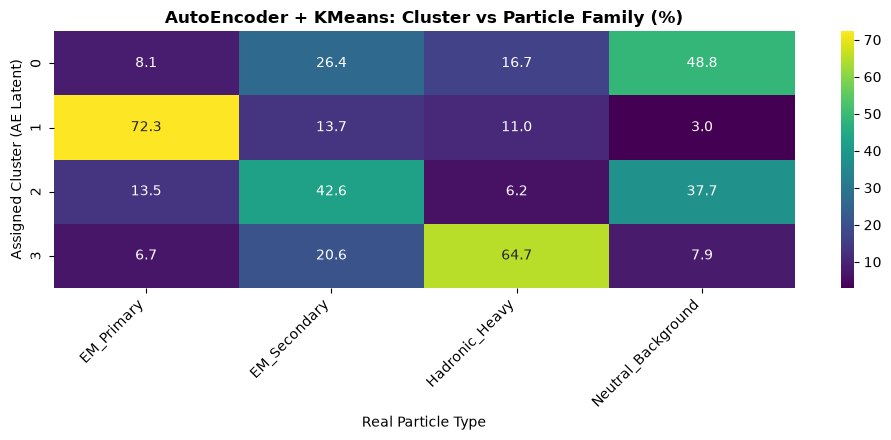

In [17]:
plot_confusion_matrix(ytest, y_pred, title_suffix, clsut_algor_algo="KMeans")

In [18]:
df_cluster = print_clustering_disribution(y_pred, ytest)
df_cluster

,Cluster,Count,Most Frequent Particle Type
0,0,777,Neutral_Background
1,1,779,EM_Primary
2,2,679,EM_Secondary
3,3,845,Hadronic_Heavy


In [19]:
# plt.figure(figsize=(10, 4.5))
# sns.scatterplot(x=z_embedded[:, 0], y=z_embedded[:, 1], hue=ytest, palette="tab10", alpha=0.7)
# plt.title("AutoEncoder Latent Space (2D) - Colored by Particle Type", fontweight="bold")
# plt.xlabel("Latent Dimension 1")
# plt.ylabel("Latent Dimension 2")
# plt.legend(title="Particle Type", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()

## Agglomerative Clustering

In [20]:
agg_clustering = AgglomerativeClustering(n_clusters=len(np.unique(ytest)))
y_pred = agg_clustering.fit_predict(z_embedded)

print("Accuracy:")
ami_AE = normalized_mutual_info_score(ytest, y_pred)
ari_AE = adjusted_rand_score(ytest, y_pred)
print(f"AMI: {np.round(ami_AE, 3)}")
print(f"ARI: {np.round(ari_AE, 3)}")

Accuracy:
AMI: 0.171
ARI: 0.147


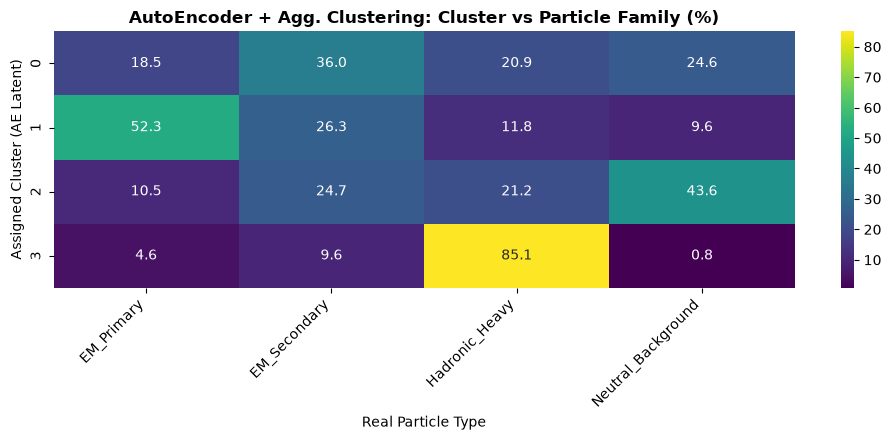

In [21]:
plot_confusion_matrix(ytest, y_pred, title_suffix, clsut_algor_algo="Agg. Clustering")

In [22]:
df_cluster = print_clustering_disribution(y_pred, ytest)
df_cluster

,Cluster,Count,Most Frequent Particle Type
0,0,508,EM_Secondary
1,1,1038,EM_Primary
2,2,1139,Neutral_Background
3,3,395,Hadronic_Heavy


## Gaussian Mixture Models

In [23]:
gmm = GaussianMixture(
    n_components=len(np.unique(ytest)),
    covariance_type='full',
    random_state=random_state,
    n_init=latent_space_dim
)
gmm.fit(z_embedded)

y_pred = gmm.predict(z_embedded)
probs_gmm = gmm.predict_proba(z_embedded)
max_conf = probs_gmm.max(axis=1)

ami_gmm = normalized_mutual_info_score(ytest, y_pred)
ari_gmm = adjusted_rand_score(ytest, y_pred)

print(f"Accuracy:")
print(f"AMI: {np.round(ami_gmm, 3)}")
print(f"ARI: {np.round(ari_gmm, 3)}\n")


Accuracy:
AMI: 0.224
ARI: 0.18



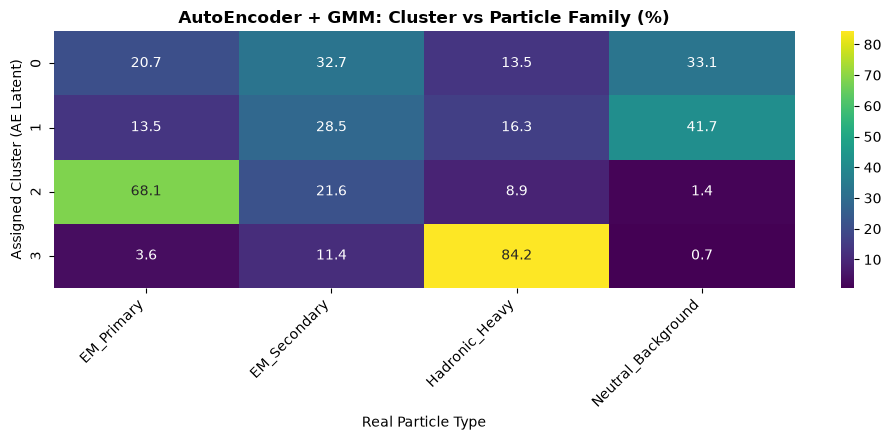

In [24]:
plot_confusion_matrix(ytest, y_pred, title_suffix, clsut_algor_algo="GMM")

In [25]:
df_cluster = print_clustering_disribution(y_pred, ytest)
df_cluster

,Cluster,Count,Most Frequent Particle Type
0,0,859,Neutral_Background
1,1,1026,Neutral_Background
2,2,643,EM_Primary
3,3,552,Hadronic_Heavy


Now select only the cluster with a probability $\ge T$ (confidence): 

In [26]:
confidence_threshold = 0.85
confident_mask = max_conf >= confidence_threshold

ytest_filtered = ytest[confident_mask]
ypred_filtered = y_pred[confident_mask]

n_total = len(ytest)
tot_mantained = confident_mask.sum()

print(f"Event with confidence >= {int(confidence_threshold*100)}%: {tot_mantained} / {n_total} ({(tot_mantained / n_total * 100):.1f}%)")

ami_conf = normalized_mutual_info_score(ytest_filtered, ypred_filtered)
ari_conf = adjusted_rand_score(ytest_filtered, ypred_filtered)
print(f"AMI: {np.round(ami_conf, 3)}")
print(f"ARI: {np.round(ari_conf, 3)}\n")


Event with confidence >= 85%: 2400 / 3080 (77.9%)
AMI: 0.29
ARI: 0.245



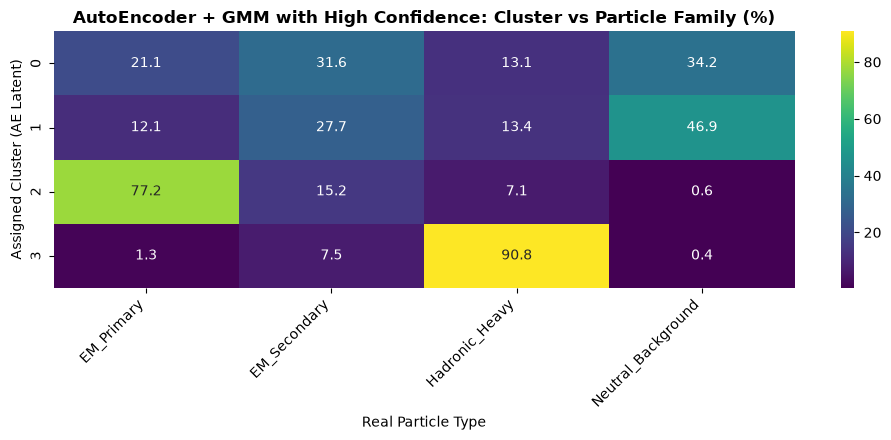

In [27]:
plot_confusion_matrix(ytest_filtered, ypred_filtered, title_suffix, clsut_algor_algo="GMM with High Confidence")

In [28]:
df_cluster = print_clustering_disribution(y_pred, ytest)
df_cluster

,Cluster,Count,Most Frequent Particle Type
0,0,859,Neutral_Background
1,1,1026,Neutral_Background
2,2,643,EM_Primary
3,3,552,Hadronic_Heavy


# 04 - Conclusions

With both the families and the single particle type the autoencoder it's able to reconstruct efficiently and with high accuracy the input with small loss value (~0.05/0.06). 

- Running the AE on paticle types: the metrics (NMI, ARI) show smaller values than the *PCA*/*Full dataset* test [see here](!./Naive_Clustering-multi_hit.ipynb)
- About clustering wrt families: (firsts test are conducted here) using macro-families rather than single particle type improve the results of the clustering algorithms. If we use macro-families the "purity" of clusters increase. With a confidence threshold applied on GMM the metrics value increase but cutting a portion of the data. 